---
# Curso: Data Mining — Semana 12 - Lunes
**Docente:** Soledad Espezúa Llerena

---
# <font color=blue>Laboratorio: Introducción a GeoPandas y shapefiles del Perú</font>

 **Ideas clave de la sesión**

- `GeoDataFrame` = tabla de pandas + columna `geometry` + CRS.
- `Point` representa ubicaciones; `Polygon` / `MultiPolygon` representan áreas.
- Los shapefiles del Perú permiten trabajar con regiones, provincias y distritos.
- Los códigos `ADM*_PCODE` son útiles para integrar distintas fuentes.
- `set_crs()` **asigna** un CRS (no mueve los puntos); `to_crs()` **transforma** las coordenadas.
- Para interpretar distancias en metros debemos trabajar con un CRS proyectado.
- Una tabla de proyecto puede asociarse a un mapa mediante una columna común (nombre o código).
- **Mapas** → GeoPandas `.plot()`. **Estilo, paletas y gráficos de tablas** → seaborn.

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd          # tablas con geometría (GeoDataFrame)
import matplotlib.pyplot as plt  # gráficos
import seaborn as sns            # estilo, paletas de colores y gráficos de tablas

pd.set_option("display.max_columns", 30)

# Estilo de seaborn para TODOS los gráficos del cuaderno.
# Importante: seaborn no dibuja mapas (no sabe qué es una geometría).
# Los mapas los dibuja GeoPandas con .plot(); seaborn les da el estilo y los colores.
sns.set_theme(style="whitegrid")

## <font color=green>0. Preparamos los archivos</font>

En el panel **Archivos** de Colab (ícono de carpeta, a la izquierda), creen una carpeta llamada `peru_shapes` y suban ahí los archivos de los shapefiles.

Un *shapefile* no es un solo archivo: el `.shp` guarda la geometría, el `.dbf` los atributos y el `.prj` el CRS. Por eso deben estar **todos juntos en la misma carpeta**.

# <font color=blue>PARTE I. De DataFrame a GeoDataFrame</font>

Partiremos de una tabla normal que contiene atributos y coordenadas.

Recuerda:

X = longitud,  
Y = latitud


## <font color=green>1. Creamos una tabla con coordenadas</font>


In [ ]:
# DataFrame tradicional: todavía no tiene una columna geometry.
# Los cuatro puntos están ubicados en Lima con fines didácticos.

df_puntos = pd.DataFrame({
    "id": [1, 2, 3, 4],
    "nombre": ["Punto A", "Punto B", "Punto C", "Punto D"],

    # X = longitud
    "longitud": [-77.0500, -77.0350, -77.0600, -77.0250],

    # Y = latitud
    "latitud": [-12.0800, -12.0950, -12.0700, -12.1050]
})

display(df_puntos)


## <font color=green>2. Convertimos la tabla en un GeoDataFrame</font>

`gpd.points_from_xy()` crea una geometría `Point` para cada fila.

Como las coordenadas son longitud/latitud provenientes de GPS, indicaremos `EPSG:4326`.


In [ ]:
# Creamos el GeoDataFrame.
# geometry contendrá un Point por observación: Point(longitud, latitud).

gdf_puntos = gpd.GeoDataFrame(
    df_puntos,
    geometry=gpd.points_from_xy(
        df_puntos["longitud"],  # X = longitud (primero)
        df_puntos["latitud"]    # Y = latitud (segundo)
    ),
    # crs NO transforma nada: solo declara que estas coordenadas
    # están en grados de longitud/latitud (como las de un GPS).
    crs="EPSG:4326"
)

display(gdf_puntos)

In [ ]:
# Revisamos el tipo de objeto, el CRS y la geometría.

print("Tipo:", type(gdf_puntos))
print("CRS:", gdf_puntos.crs)

print("\nGeometrías:")
display(gdf_puntos[["id", "nombre", "geometry"]])


### Observación

Un `GeoDataFrame` conserva los atributos de pandas, pero añade una columna espacial:

```text
POINT (-77.05 -12.08)
```

Ese punto se lee como `POINT (X Y)`:

- X = longitud = -77.05 (negativa: al oeste de Greenwich);
- Y = latitud = -12.08 (negativa: al sur del Ecuador).

En el Perú la longitud va aproximadamente de -69 a -81 y la latitud de 0 a -18. Si ven una "latitud" de -77, invirtieron el orden.

# <font color=blue>PARTE II. Shapefiles administrativos del Perú</font>

Los shapefiles que utilizaremos representan distintos niveles administrativos.

| Nivel | Representa | Ejemplo |
|---|---|---|
| **ADM0** | País | Perú |
| **ADM1** | Región / departamento | Lima, Cusco, Arequipa |
| **ADM2** | Provincia | Lima, Cañete, Arequipa |
| **ADM3** | Distrito | Miraflores, Jesús María, Yanahuara |

Estos archivos contienen tanto la **geometría** como atributos y códigos administrativos.


## <font color=green>3. Cargamos regiones, provincias y distritos</font>


In [ ]:
# Rutas de los shapefiles (relativas a la carpeta donde está el cuaderno).
# Basta con indicar el .shp: GeoPandas lee automáticamente el .dbf, .shx y .prj
# que tienen el mismo nombre y están en la misma carpeta.

ruta_adm0 = "peru_shapes/per_admbnda_adm0_ign_20200714.shp"   # país
ruta_adm1 = "peru_shapes/per_admbnda_adm1_ign_20200714.shp"   # regiones
ruta_adm2 = "peru_shapes/per_admbnda_adm2_ign_20200714.shp"   # provincias
ruta_adm3 = "peru_shapes/per_admbnda_adm3_ign_20200714.shp"   # distritos

# Leemos los archivos con GeoPandas (los distritos pueden tardar unos segundos).
peru       = gpd.read_file(ruta_adm0)
regiones   = gpd.read_file(ruta_adm1)
provincias = gpd.read_file(ruta_adm2)
distritos  = gpd.read_file(ruta_adm3)

print("Países       :", len(peru))
print("Regiones     :", len(regiones))    # 24 departamentos + Callao
print("Provincias   :", len(provincias))
print("Distritos    :", len(distritos))

## <font color=green>4. Exploramos atributos y códigos administrativos</font>

Los nombres (`ADM*_ES`) son útiles para lectura humana, pero los códigos (`ADM*_PCODE`) son más seguros para integrar diferentes bases de datos.

Ojo: en este archivo los nombres van **sin tildes** (`Apurimac`, `Junin`, `San Martin`, `Huanuco`). Si su tabla escribe "Junín", no coincidirá con "Junin".

In [ ]:
# Regiones del Perú.
# ADM1_ES contiene el nombre de la región.
# ADM1_PCODE contiene su código administrativo.

display(
    regiones[
        ["ADM1_ES", "ADM1_PCODE", "geometry"]
    ].head()
)


In [ ]:
# Observamos cómo se construye la jerarquía en los distritos.

# ADM1 = región
# ADM2 = provincia
# ADM3 = distrito

display(
    distritos[
        [
            "ADM1_ES", "ADM1_PCODE",
            "ADM2_ES", "ADM2_PCODE",
            "ADM3_ES", "ADM3_PCODE"
        ]
    ].head(10)
)


## <font color=green>5. Revisamos el CRS</font>


In [ ]:
# GeoPandas leyó el CRS desde el archivo .prj de cada shapefile.
# EPSG:4326 = longitud/latitud en grados.

print("CRS regiones  :", regiones.crs)
print("CRS provincias:", provincias.crs)
print("CRS distritos :", distritos.crs)

## <font color=green>6. Visualizamos las regiones del Perú</font>


In [ ]:
# Cada fila de regiones contiene un Polygon o MultiPolygon.
# facecolor = color de relleno; edgecolor = color del borde.

ax = regiones.plot(
    figsize=(7, 9),
    facecolor="white",
    edgecolor="black"
)

ax.set_title("Regiones del Perú")
ax.set_axis_off()   # oculta los ejes (están en grados)

plt.show()

# <font color=blue>PARTE III. Filtrar y representar niveles administrativos</font>

Como un `GeoDataFrame` también es una tabla, podemos filtrar filas usando condiciones de pandas.


## <font color=green>7. Seleccionamos las provincias de la región Lima</font>

In [ ]:
# Seleccionamos solo las provincias pertenecientes a la región Lima.
# Es un filtro de pandas: provincias["ADM1_ES"] == "Lima" devuelve True/False por fila.
# .copy() evita advertencias si luego modificamos el resultado.

provincias_lima = provincias[
    provincias["ADM1_ES"] == "Lima"
].copy()

print("Número de provincias:", len(provincias_lima))

display(
    provincias_lima[
        ["ADM2_ES", "ADM2_PCODE"]
    ].sort_values("ADM2_ES")
)

In [ ]:
# Visualizamos las provincias seleccionadas.

ax = provincias_lima.plot(
    figsize=(8, 6),
    facecolor="white",
    edgecolor="black"
)

ax.set_title("Provincias de la región Lima")
ax.set_axis_off()

plt.show()


In [ ]:
# Ejemplo: graficar las provincias de la región Lima con sus nombres.
ax = provincias_lima.plot(
    figsize=(10, 8),
    facecolor="white",
    edgecolor="black"
)

# Recorremos cada provincia y escribimos su nombre.
for idx, row in provincias_lima.iterrows():
    # representative_point() garantiza un punto DENTRO del polígono
    # (el centroide podría caer fuera en formas irregulares).
    coords = row["geometry"].representative_point().coords[0]
    ax.annotate(
        text=row["ADM2_ES"],
        xy=coords,
        horizontalalignment="center",
        fontsize=8,
        color="blue"
    )

ax.set_title("Provincias de la región Lima con nombres")
ax.set_axis_off()
plt.show()

In [ ]:
# Mismo mapa, coloreando cada provincia con la paleta "pastel" de seaborn.
# sns.color_palette("pastel", n) devuelve n colores; GeoPandas pinta
# cada fila (cada provincia) con un color de la lista.

colores = sns.color_palette("pastel", len(provincias_lima))

ax = provincias_lima.plot(
    figsize=(10, 8),
    color=colores,
    edgecolor="grey",
    linewidth=0.5
)

for idx, row in provincias_lima.iterrows():
    coords = row["geometry"].representative_point().coords[0]
    ax.annotate(
        text=row["ADM2_ES"],
        xy=coords,
        horizontalalignment="center",
        fontsize=8,
        color="#333333"
    )

ax.set_title("Provincias de la región Lima (paleta pastel de seaborn)", fontsize=14, pad=10)
ax.set_axis_off()
plt.show()

## <font color=green>8. Seleccionamos los distritos de la provincia de Lima</font>


In [ ]:
# Usamos dos condiciones porque la región Lima tiene 10 provincias
# y queremos solo los distritos de la PROVINCIA de Lima.
# Cada condición va entre paréntesis y se combinan con & ("y").

distritos_lima = distritos[
    (distritos["ADM1_ES"] == "Lima") &  # región = Lima
    (distritos["ADM2_ES"] == "Lima")    # provincia = Lima
].copy()

print("Número de distritos:", len(distritos_lima))

display(
    distritos_lima[
        ["ADM3_ES", "ADM3_PCODE"]
    ].sort_values("ADM3_ES").head(20)
)

In [ ]:
# Representamos los distritos de la provincia de Lima.

ax = distritos_lima.plot(
    figsize=(8, 8),
    facecolor="white",
    edgecolor="black"
)

ax.set_title("Distritos de la provincia de Lima")
ax.set_axis_off()

plt.show()

# <font color=blue>PARTE IV. Trabajamos con capas</font>

Una idea central del análisis geoespacial es representar varias capas sobre un mismo mapa.

Por ejemplo:

- polígonos: distritos;
- puntos: clientes, sensores, tiendas, accidentes, etc.


## <font color=green>9. Superponemos puntos sobre los distritos de Lima</font>


In [ ]:
# Antes de superponer capas revisamos que compartan el mismo CRS.

print("CRS distritos:", distritos_lima.crs)
print("CRS puntos   :", gdf_puntos.crs)


In [ ]:
# Si los CRS fueran distintos, primero transformamos los puntos al CRS de los distritos.
# Aquí ambos ya están en EPSG:4326, así que to_crs() no cambia nada;
# lo dejamos como buena práctica.

gdf_puntos_mapa = gdf_puntos.to_crs(
    distritos_lima.crs
)

# 1) Dibujamos primero los polígonos (el fondo).
ax = distritos_lima.plot(
    figsize=(8, 8),
    facecolor="white",
    edgecolor="gray"
)

# 2) Agregamos los puntos sobre el MISMO eje: ax=ax es la clave.
gdf_puntos_mapa.plot(
    ax=ax,
    color="red",
    markersize=50
)

ax.set_title("Capas: distritos de Lima + puntos")
ax.set_axis_off()

plt.show()

# <font color=blue>PARTE V. CRS y reproyección</font>

Esta es la idea más importante antes de trabajar con distancias espaciales.

- `EPSG:4326` expresa longitud y latitud en **grados**.
- un CRS proyectado puede expresar coordenadas en **metros**.


## <font color=green>10. `set_crs()` y `to_crs()` no hacen lo mismo</font>

| | `set_crs()` | `to_crs()` |
|---|---|---|
| ¿Qué hace? | **Asigna**: declara en qué CRS *ya están* las coordenadas | **Transforma**: recalcula las coordenadas en otro CRS |
| ¿Cambian los números? | No | Sí |
| ¿Cuándo se usa? | Cuando `gdf.crs` es `None` (por ejemplo, datos de un CSV) | Cuando necesitamos otro CRS (por ejemplo, metros) |

Analogía: `set_crs()` es escribir "soles" en el encabezado de una columna de montos; `to_crs()` es convertir esos soles a dólares.

Error común: usar `set_crs()` para "pasar a metros". Las coordenadas seguirían en grados, pero etiquetadas como metros, y todos los cálculos saldrían mal **sin ningún mensaje de error**.

In [ ]:
# Veámoslo con código.
# 1) Un GeoDataFrame SIN CRS (como cuando las coordenadas vienen de un CSV).

gdf_sin_crs = gpd.GeoDataFrame(
    df_puntos,
    geometry=gpd.points_from_xy(df_puntos["longitud"], df_puntos["latitud"])
)
print("CRS inicial          :", gdf_sin_crs.crs)   # None: GeoPandas no sabe en qué unidades están

# 2) set_crs(): solo declara el CRS. Las coordenadas NO cambian.
gdf_con_crs = gdf_sin_crs.set_crs("EPSG:4326")
print("CRS después de set_crs:", gdf_con_crs.crs)
print("Primer punto          :", gdf_con_crs.geometry.iloc[0])

## <font color=green>11. Reproyectamos los puntos de Lima a metros</font>

UTM divide el mundo en zonas; el Perú cae en tres (17S, 18S y 19S). No hace falta memorizarlas: `estimate_utm_crs()` elige la zona adecuada según la ubicación de los datos. Solo funciona si el GeoDataFrame ya tiene un CRS definido.

In [ ]:
# Estimamos un CRS UTM apropiado para estos puntos.
# Para Lima debería ser EPSG:32718 (WGS 84 / UTM zona 18S).

crs_metros = gdf_puntos.estimate_utm_crs()

print("CRS estimado:", crs_metros)
print("Nombre      :", crs_metros.name)

In [ ]:
# Reproyectamos los puntos con to_crs().
# Las nuevas coordenadas están en metros: compárenlas con POINT (-77.05 -12.08).

gdf_puntos_m = gdf_puntos.to_crs(crs_metros)

display(gdf_puntos_m[["id", "nombre", "geometry"]])

In [ ]:
print("CRS:",gdf_puntos_m.crs) # Verificamos la transformación a metros

## <font color=green>12. Comparamos distancia en grados y distancia en metros</font>


In [ ]:
# Distancia entre el Punto A y el Punto B usando las geometrías en longitud/latitud.
# El resultado está en GRADOS, y un grado no es una distancia fija:
# en Lima, 1° de longitud ≈ 109 km y 1° de latitud ≈ 111 km.
# Por eso este número no tiene interpretación física directa.

distancia_grados = (
    gdf_puntos.geometry.iloc[0]
    .distance(gdf_puntos.geometry.iloc[1])
)

print("Distancia en grados:", round(distancia_grados, 6))

In [ ]:
# La misma distancia después de reproyectar.
# Como el CRS usa metros, el resultado sí tiene interpretación física.

distancia_metros = (
    gdf_puntos_m.geometry.iloc[0]
    .distance(gdf_puntos_m.geometry.iloc[1])
)

print("Distancia aproximada en metros:", round(distancia_metros, 2))
print("Distancia aproximada en km:", round(distancia_metros / 1000, 3))

In [ ]:
print("CRS:",gdf_puntos_m.crs)

### Idea clave

Para medir distancias o áreas físicas:

**grados (EPSG:4326)** → `to_crs()` → **metros (CRS proyectado, por ejemplo UTM)**

Esta idea será fundamental en la siguiente sesión con **DBSCAN espacial**: `DBSCAN(eps=1000)` significa un radio de 1 km **solo si** las coordenadas están en metros. En grados, `eps=1000` abarcaría el planeta entero.

# <font color=blue>PARTE VI. Relacionar datos de un proyecto con un mapa</font>

Muchas veces nuestros datos no contienen una geometría, pero sí el nombre o código de una región, provincia o distrito.

En ese caso podemos unir la tabla del proyecto con el shapefile mediante una clave común.


## <font color=green>13. Ejemplo: unir una variable tabular con las regiones</font>


Simulamos los datos de un proyecto (por ejemplo, Lima: 80; Arequipa: 55; ...) que uniremos al shapefile de regiones para poder mapearlos.

In [ ]:
# Creamos una tabla didáctica con un valor asociado a algunas regiones.
# En un proyecto real, esta tabla podría venir de un CSV o Excel.

df_indicador = pd.DataFrame({
    "ADM1_ES": ["Lima", "Arequipa", "Cusco", "Piura", "Loreto"],
    "valor": [80, 55, 70, 45, 35]
})

display(df_indicador)


In [ ]:
# Unimos la tabla con el GeoDataFrame de regiones usando el nombre de la región.
# - El GeoDataFrame va a la IZQUIERDA (regiones.merge(...)) para que el resultado
#   siga siendo un GeoDataFrame con su columna geometry.
# - how="left" conserva las 25 regiones; las que no tienen dato quedan con NaN.
# - Los nombres deben coincidir exactamente ("Lima" ≠ "LIMA" ≠ "Lima ").
#   En proyectos reales es preferible usar un código como ADM1_PCODE.

mapa_indicador = regiones.merge(
    df_indicador,
    on="ADM1_ES",
    how="left"
)

display(
    mapa_indicador[
        ["ADM1_ES", "ADM1_PCODE", "valor", "geometry"]
    ].head()
)

**Graficamos el indicador.** Las regiones sin dato (NaN) se pintan de gris con `missing_kwds`.

In [ ]:
# Ahora la variable tabular puede representarse espacialmente (mapa coroplético).
# cmap="rocket_r": paleta de seaborn invertida (_r), así los valores ALTOS
# se ven oscuros y los bajos claros, que es lo más fácil de leer.

ax = mapa_indicador.plot(
    column="valor",
    cmap="rocket_r",
    figsize=(7, 9),
    edgecolor="gray",
    legend=True,
    legend_kwds={"label": "valor"},
    missing_kwds={"color": "lightgray"}   # regiones sin dato
)

ax.set_title("Ejemplo: indicador asociado a regiones")
ax.set_axis_off()

plt.show()

In [ ]:
print("CRS:",mapa_indicador.crs)

Los mismos datos como **gráfico de barras con seaborn**. Para comparar valores exactos, una barra suele ser más clara que un color en el mapa; el mapa muestra **dónde** están.

In [ ]:
# seaborn trabaja con la tabla (df_indicador), no con las geometrías.
ax = sns.barplot(
    data=df_indicador.sort_values("valor", ascending=False),
    x="valor",
    y="ADM1_ES",
    hue="valor",            # el color depende del valor (como en el mapa)
    palette="rocket_r",     # la misma paleta del mapa: valores altos = oscuro
    legend=False
)
ax.set_title("Indicador por región")
ax.set_xlabel("valor")
ax.set_ylabel("región")
plt.show()

In [ ]:
# Versión mínima del mismo mapa.
# Observen: sin missing_kwds, las regiones sin dato (NaN) NO se dibujan.
# Y sin set_axis_off(), los ejes muestran longitud y latitud en grados.

mapa_indicador.plot(
    column="valor",
    legend=True
)
plt.show()

## Otras paletas de seaborn

GeoPandas acepta las paletas de seaborn (`"rocket"`, `"mako"`, `"flare"`, `"crest"`) porque importamos `seaborn` al inicio. Sin `import seaborn`, `cmap="rocket"` daría error.

Comparen con el mapa anterior: en `"rocket"` los valores **bajos** son oscuros y los altos claros; con `"rocket_r"` (invertida) es al revés. Siempre lean la leyenda.

In [ ]:
# Paleta "rocket" sin invertir. Prueben también "mako", "flare" o "crest".
mapa_indicador.plot(
    figsize=(6, 6),
    edgecolor="black",
    column="valor",
    cmap="rocket",
    legend=True,
    #missing_kwds={"color": "lightgray"}   # descomenten para ver las regiones sin dato
)
plt.show()

# <font color=blue>DESAFÍO</font>

## <font color=green>A. Regiones costeras</font>

Construyan un mapa del Perú y destaquen las regiones de la costa.

Pueden utilizar como punto de partida:

```python
regiones_costa = [
    "Tumbes", "Piura", "Lambayeque", "La Libertad", "Ancash",
    "Lima", "Callao", "Ica", "Arequipa", "Moquegua", "Tacna"
]
```

Deben:

1. seleccionar las regiones mediante `.isin()`;
2. dibujar todas las regiones como contexto;
3. superponer las regiones costeras (pista: `ax=ax`, como en la sección 9).





---



### Solución esperada

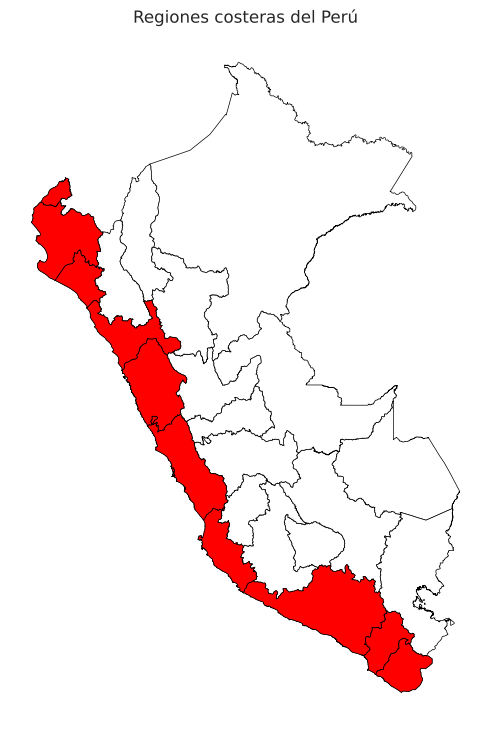

## <font color=green>B. Una región de interés</font>

Elijan una región del Perú relacionada con su proyecto o de su interés:

1. muestren sus provincias;
2. seleccionen una provincia;
3. muestren los distritos de esa provincia.

Recuerden que los nombres van sin tildes (`"Junin"`, `"San Martin"`); pueden revisarlos con `sorted(regiones["ADM1_ES"])`.



## <font color=green>C. Proyecto</font>

Si su proyecto dispone de información geográfica, indiquen:

- qué nivel geográfico utilizan (región, provincia, distrito o coordenadas);
- qué columna permitiría relacionar su base con un shapefile;
- si la ubicación se usará para **visualizar resultados** o formará parte directa del análisis.

Si el proyecto no tiene componente espacial, no es necesario inventarlo.



## <font color=green>D. (Opcional) Área de la costa</font>

Calculen el área total de las regiones costeras en km².

Pistas: reproyecten con `estimate_utm_crs()` y `to_crs()`; luego `.area` devuelve m² (dividan entre 1 000 000). Deberían obtener alrededor de **267 000 km²**.

Para pensar: ¿qué obtienen si calculan `.area` sin reproyectar? ¿Y si usan una zona UTM de otra parte del mundo, como `EPSG:32629`?